# Solving an MIS problem with QUBO Solver 

The goal of the tutorial is to show how to solve a **Maximum Independent Set (MIS) problem using QUBO Solver**.


## Mapping MIS to QUBO

Each node $i$ in the graph is assigned a binary variable $x_i \in \{0, 1\}$, where **$x_i = 1$ means node $i$ is selected** as part of the independent set.

The MIS problem is then written as the following QUBO minimization:

$$\min_x \; -\sum_i x_i + P \sum_{(i,j) \in E} x_i x_j$$

The objective has two competing terms:

- **$-\sum_i x_i$** — minimizing this encourages selecting *as many nodes as possible*, since each selected node decreases the objective.
- **$P \sum_{(i,j) \in E} x_i x_j$** — for every edge $(i,j)$, if *both* endpoints are selected ($x_i = 1$ and $x_j = 1$), this term adds a penalty $P$ to the objective, discouraging invalid selections.

$P$ is a penalty parameter that must be large enough to ensure that no two adjacent nodes are ever both selected in the optimal solution. The choice of $P$ can influence the quality of the results — too small and the penalty may be insufficient to rule out invalid solutions, too large and it may distort the energy landscape. It is therefore worth tuning $P$ depending on the structure of the graph.

## Why use the QUBO Solver to resolve an MIS problem? 

MIS maps cleanly to QUBO. The MIS problem can be reformulated as a Quadratic Unconstrained Binary Optimization (QUBO) problem: assign a binary variable to each node, maximize the number of selected nodes, and penalize any pair of connected nodes that are both selected. This yields a QUBO matrix that the library consumes directly.

## Mapping MIS to QUBO

Each node $i$ in the graph is assigned a binary variable $x_i \in \{0, 1\}$, where **$x_i = 1$ means node $i$ is selected** as part of the independent set.

The MIS problem is then written as the following QUBO minimization:

$$\min_x \; -\sum_i x_i + P \sum_{(i,j) \in E} x_i x_j$$

The objective has two competing terms:

- **$-\sum_i x_i$** — minimizing this encourages selecting *as many nodes as possible*, since each selected node decreases the objective.
- **$P \sum_{(i,j) \in E} x_i x_j$** — for every edge $(i,j)$, if *both* endpoints are selected ($x_i = 1$ and $x_j = 1$), this term adds a penalty $P$ to the objective, discouraging invalid selections.

$P$ is a penalty parameter that must be large enough to ensure that no two adjacent nodes are ever both selected in the optimal solution. The choice of $P$ can influence the quality of the results — too small and the penalty may be insufficient to rule out invalid solutions, too large and it may distort the energy landscape. It is therefore worth tuning $P$ depending on the structure of the graph.

Once this mapping has be done, the solver finds the assignment of $x_i$ values that maximises the number of selected nodes while avoiding any pair of connected nodes — which is exactly the MIS problem.

## Practical example

### Step 1: Define your graph

For the sake of this tutorial, we will use a simple `networkx` **Unit Disk Graph with 6 nodes** as input, as it is easy to understand and visualize. 

Nodes : [0, 1, 2, 3, 4, 5]
Edges : [(0, 1), (0, 2), (1, 3), (2, 3), (3, 4), (3, 5)]


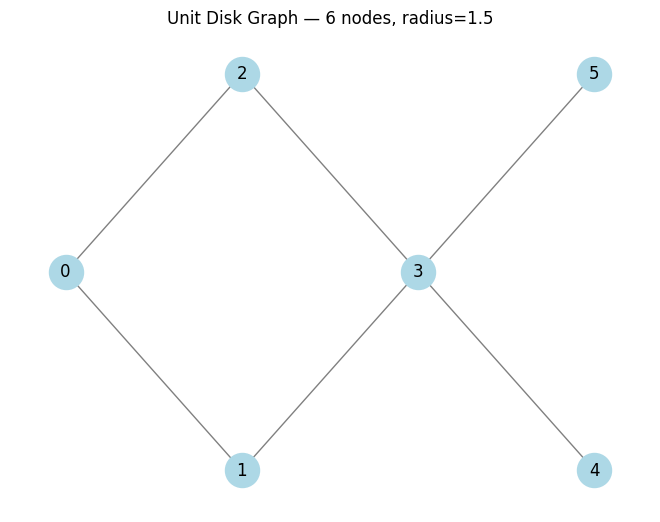

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Node positions in 2D space
pos = {
    0: (0.0, 1.0),
    1: (1.0, 0.0),
    2: (1.0, 2.0),
    3: (2.0, 1.0),
    4: (3.0, 0.0),
    5: (3.0, 2.0),
}

# Build Unit Disk Graph: connect nodes within distance threshold
radius = 1.5
G = nx.Graph()
G.add_nodes_from(pos.keys())
for i in pos:
    for j in pos:
        if i < j:
            dist = np.linalg.norm(np.array(pos[i]) - np.array(pos[j]))
            if dist <= radius:
                G.add_edge(i, j)

print(f"Nodes : {list(G.nodes())}")
print(f"Edges : {list(G.edges())}")

nx.draw(G, pos=pos, with_labels=True, node_color="lightblue",
        node_size=600, font_size=12, edge_color="gray")
plt.title(f"Unit Disk Graph — 6 nodes, radius={radius}")
plt.show()

In [2]:
from qubosolver import Instance, Solver, SolverConfig, matrix

# define QUBO
Q = matrix.tensor([
    [-4.0, 1.0, 2.0, 1.5, 2.3, 0.9, 1.8, 2.7, 1.2],
    [ 1.0,-3.2, 1.7, 2.1, 0.8, 1.9, 2.2, 1.1, 1.6],
    [ 2.0, 1.7,-5.1, 0.7, 2.5, 1.3, 2.6, 1.4, 2.0],
    [ 1.5, 2.1, 0.7,-2.7, 1.2, 2.4, 0.6, 1.8, 2.1],
    [ 2.3, 0.8, 2.5, 1.2,-6.3, 1.0, 1.7, 2.8, 1.5],
    [ 0.9, 1.9, 1.3, 2.4, 1.0,-4.5, 2.3, 1.6, 0.9],
    [ 1.8, 2.2, 2.6, 0.6, 1.7, 2.3,-3.8, 1.2, 2.2],
    [ 2.7, 1.1, 1.4, 1.8, 2.8, 1.6, 1.2,-5.9, 1.4],
    [ 1.2, 1.6, 2.0, 2.1, 1.5, 0.9, 2.2, 1.4,-2.4],
])
instance = Instance(Q)

# Create a SolverConfig object. The default config solves using a quantum approach on a local emulator.
config = SolverConfig()

# Instantiate the solver.
solver = Solver(instance, config)

# Solve the QUBO problem.
quantum_solution = solver.solve()

In [3]:
quantum_solution

Solution(bitstrings=tensor([[0, 0, 0, 0, 1, 1, 0, 0, 0],
        [0, 0, 1, 0, 0, 0, 0, 1, 0],
        [0, 0, 0, 0, 0, 1, 0, 1, 0],
        [0, 0, 1, 0, 0, 1, 0, 0, 0],
        [0, 0, 0, 0, 1, 0, 1, 0, 0],
        [0, 0, 0, 1, 1, 0, 0, 0, 0],
        [0, 0, 1, 1, 0, 0, 0, 0, 0]], dtype=torch.int8), costs=tensor([-8.8000, -8.2000, -7.2000, -7.0000, -6.7000, -6.6000, -6.4000]), counts=tensor([  1, 159, 749,   2,   8,  54,  27]), probabilities=tensor([0.0010, 0.1590, 0.7490, 0.0020, 0.0080, 0.0540, 0.0270]))

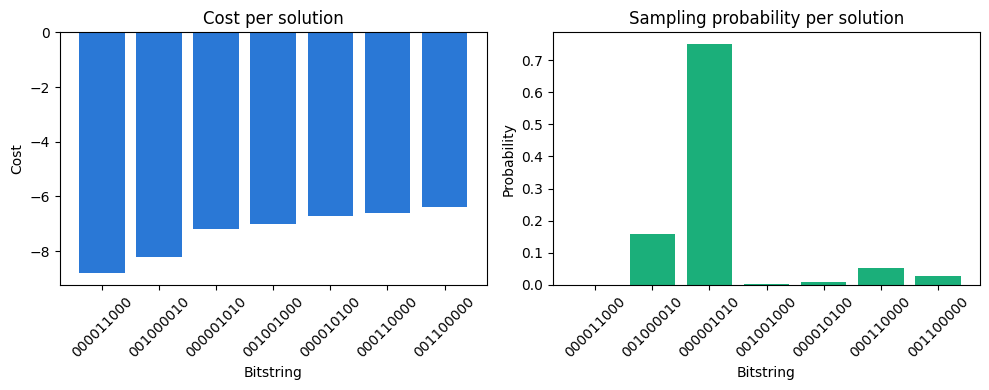

In [4]:
import matplotlib.pyplot as plt

bitstrings = ["".join(map(str, row.tolist())) for row in quantum_solution.bitstrings]
costs = quantum_solution.costs.tolist()
probabilities = quantum_solution.probabilities.tolist()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(bitstrings, costs, color="#2a78d6")
axes[0].set_title("Cost per solution")
axes[0].set_xlabel("Bitstring")
axes[0].set_ylabel("Cost")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(bitstrings, probabilities, color="#1baf7a")
axes[1].set_title("Sampling probability per solution")
axes[1].set_xlabel("Bitstring")
axes[1].set_ylabel("Probability")
axes[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

In [5]:
from qubosolver import ClassicalSolvingConfig, Instance, Solver, SolverConfig, matrix

# define QUBO
Q = matrix.tensor([
    [-4.0, 1.0, 2.0, 1.5, 2.3, 0.9, 1.8, 2.7, 1.2],
    [ 1.0,-3.2, 1.7, 2.1, 0.8, 1.9, 2.2, 1.1, 1.6],
    [ 2.0, 1.7,-5.1, 0.7, 2.5, 1.3, 2.6, 1.4, 2.0],
    [ 1.5, 2.1, 0.7,-2.7, 1.2, 2.4, 0.6, 1.8, 2.1],
    [ 2.3, 0.8, 2.5, 1.2,-6.3, 1.0, 1.7, 2.8, 1.5],
    [ 0.9, 1.9, 1.3, 2.4, 1.0,-4.5, 2.3, 1.6, 0.9],
    [ 1.8, 2.2, 2.6, 0.6, 1.7, 2.3,-3.8, 1.2, 2.2],
    [ 2.7, 1.1, 1.4, 1.8, 2.8, 1.6, 1.2,-5.9, 1.4],
    [ 1.2, 1.6, 2.0, 2.1, 1.5, 0.9, 2.2, 1.4,-2.4],
])
instance = Instance(Q)

# Create a SolverConfig object with classical solver options.
classical_config = ClassicalSolvingConfig(
    algorithm="tabu_search",
    time_limit=10.0,
)
config = SolverConfig(solving=classical_config)

# Instantiate the solver.
solver = Solver(instance, config)

# Solve the QUBO problem.
classical_solution = solver.solve()

In [6]:
classical_solution

Solution(bitstrings=tensor([[0, 0, 0, 0, 1, 1, 0, 0, 0]], dtype=torch.int8), costs=tensor([-8.8000]), counts=tensor([1]), probabilities=tensor([1.]))

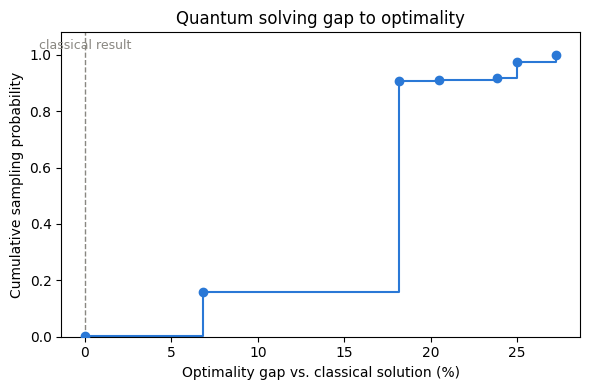

In [7]:
import matplotlib.pyplot as plt

optimal_cost = classical_solution.costs.min().item()

gaps_percent = 100.0 * (quantum_solution.costs - optimal_cost) / abs(optimal_cost)
probabilities = quantum_solution.probabilities

order = gaps_percent.argsort()
sorted_gaps = gaps_percent[order].tolist()
cumulative_probabilities = probabilities[order].cumsum(dim=0).tolist()

fig, ax = plt.subplots(figsize=(6, 4))
ax.step(
    [sorted_gaps[0]] + sorted_gaps,
    [0.0] + cumulative_probabilities,
    where="post",
    color="#2a78d6",
)
ax.scatter(sorted_gaps, cumulative_probabilities, color="#2a78d6", zorder=3)
ax.axvline(0.0, color="#898781", linestyle="--", linewidth=1)
ax.text(0.0, 1.02, "classical result", color="#898781", ha="center", fontsize=9)

ax.set_title("Quantum solving gap to optimality")
ax.set_xlabel("Optimality gap vs. classical solution (%)")
ax.set_ylabel("Cumulative sampling probability")
ax.set_ylim(0, 1.08)
fig.tight_layout()
plt.show()